In [1]:
!pip install legacy-cgi --quiet
!pip install transformers --quiet
!pip install opendatasets --quiet

import opendatasets as od
od.download("https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: rajanprasad3
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection


100%|██████████| 3.30M/3.30M [00:00<00:00, 201MB/s]

In [2]:
import torch
import torch.nn as nn
from torch.optim import Adam
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Available Device: ', device)

Available Device:  cuda


In [3]:
data_df = pd.read_json('/content/news-headlines-dataset-for-sarcasm-detection/Sarcasm_Headlines_Dataset.json', lines = True)
data_df.dropna(inplace = True)
data_df.drop_duplicates(inplace=True)
data_df.drop(columns=['article_link'], inplace = True)
data_df.head()

,headline,is_sarcastic
0,former versace store clerk sues over secret 'b...,0
1,the 'roseanne' revival catches up to our thorn...,0
2,mom starting to fear son's web series closest ...,1
3,"boehner just wants wife to listen, not come up...",1
4,j.k. rowling wishes snape happy birthday in th...,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(np.array(data_df['headline']), np.array(data_df['is_sarcastic']), test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5)

print("Training Size: ", X_train.shape[0], " row Which is: ", round(X_train.shape[0]/data_df.shape[0], 4) * 100, "%")
print("Validation Size: ", X_val.shape[0], " row Which is: ", round(X_val.shape[0]/data_df.shape[0], 4) * 100, "%")
print("Testing Size: ", X_test.shape[0], " row Which is: ", round(X_test.shape[0]/data_df.shape[0], 4) * 100, "%")

Training Size:  18695  row Which is:  70.0 %
Validation Size:  4006  row Which is:  15.0 %
Testing Size:  4007  row Which is:  15.0 %


In [5]:
tokenizer = AutoTokenizer.from_pretrained('google-bert/bert-base-uncased')
bert_model = AutoModel.from_pretrained('google-bert/bert-base-uncased')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [11]:
class dataset(Dataset):
  def __init__(self, X, y):
    # Tokenize input texts
    self.encodings = tokenizer(
        list(X),
        max_length=100,
        truncation=True,
        padding="max_length",
        return_tensors='pt')
    # Move tensors to device
    self.encodings = {key: val.to(device) for key, val in self.encodings.items()}
    self.Y = torch.tensor(y, dtype=torch.float32).to(device)

  def __len__(self):
    return len(self.Y)

  def __getitem__(self, idx):
    item = {key: val[idx] for key, val in self.encodings.items()}
    item['labels'] = self.Y[idx]
    return item

train_data = dataset(X_train, y_train)
val_data = dataset(X_val, y_val)
test_data = dataset(X_test, y_test)

In [12]:
Batch_size = 32
Epochs = 10
lr = 1e-4

In [14]:
train_dataloader = DataLoader(train_data, batch_size = Batch_size, shuffle=True)
val_dataloader = DataLoader(val_data, batch_size = Batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size = Batch_size, shuffle=True)

In [15]:
class MyModel(nn.Module):
  def __init__(self, bert_model):
    super(MyModel, self).__init__()
    self.bert = bert_model
    self.dropout = nn.Dropout(0.25)
    self.linear1 = nn.Linear(768, 384) # bert model representation size is 768
    self.linear2 = nn.Linear(384, 1)
    self.sigmoid = nn.Sigmoid()
  def forward(self, input_ids, attention_mask):
    pooled_outputs = self.bert(input_ids, attention_mask, return_dict = False)[0][:,0]
    output = self.linear1(pooled_outputs)
    output = self.dropout(output)
    output = self.linear2(output)
    output = self.sigmoid(output)
    return output

In [16]:
for param in bert_model.parameters():
  param.requires_grad = False
model = MyModel(bert_model).to(device)

In [19]:
model

MyModel(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=Tr

In [20]:
criterion = nn.BCELoss()
optimizer = Adam(model.parameters(), lr = lr)

In [23]:
total_loss_train_plot = []
total_loss_val_plot = []
total_acc_train_plot = []
total_acc_val_plot = []

for epoch in range(Epochs):
  total_acc_train = 0
  total_loss_train = 0
  total_acc_val = 0
  total_loss_val = 0

  model.train()
  for indx, data in enumerate(train_dataloader):
    inputs = data
    labels = data['labels']

    # Forward pass
    prediction = model(inputs['input_ids'], inputs['attention_mask'].squeeze(1)).squeeze(1)
    batch_loss = criterion(prediction, labels)
    total_loss_train += batch_loss.item()

    acc = (prediction.round() == labels).sum().item()
    total_acc_train += acc

    batch_loss.backward()
    optimizer.step()
    optimizer.zero_grad()

  model.eval()
  with torch.no_grad():
    for indx, data in enumerate(val_dataloader):
      inputs = data
      labels = data['labels']

      prediction = model(inputs['input_ids'], inputs['attention_mask'].squeeze(1)).squeeze(1)
      batch_loss = criterion(prediction, labels)
      total_loss_val += batch_loss.item()

      acc = (prediction.round() == labels).sum().item()
      total_acc_val += acc

  # Compute averages per epoch
  epoch_train_loss = total_loss_train / len(train_dataloader)
  epoch_val_loss = total_loss_val / len(val_dataloader)
  epoch_train_acc = (total_acc_train / len(train_data)) * 100
  epoch_val_acc = (total_acc_val / len(val_data)) * 100

  total_loss_train_plot.append(epoch_train_loss)
  total_loss_val_plot.append(epoch_val_loss)
  total_acc_train_plot.append(epoch_train_acc)
  total_acc_val_plot.append(epoch_val_acc)

  print(f"""Epoch No: {epoch + 1} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%
             | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%""")

Epoch No: 1 | Train Loss: 0.4742 | Train Acc: 78.65%
             | Val Loss: 0.3926 | Val Acc: 82.25%
Epoch No: 2 | Train Loss: 0.3992 | Train Acc: 82.94%
             | Val Loss: 0.3585 | Val Acc: 83.70%
Epoch No: 3 | Train Loss: 0.3836 | Train Acc: 83.34%
             | Val Loss: 0.3501 | Val Acc: 83.97%
Epoch No: 4 | Train Loss: 0.3721 | Train Acc: 83.77%
             | Val Loss: 0.3456 | Val Acc: 85.12%
Epoch No: 5 | Train Loss: 0.3733 | Train Acc: 83.82%
             | Val Loss: 0.3319 | Val Acc: 85.60%
Epoch No: 6 | Train Loss: 0.3709 | Train Acc: 83.78%
             | Val Loss: 0.3401 | Val Acc: 85.42%
Epoch No: 7 | Train Loss: 0.3687 | Train Acc: 83.89%
             | Val Loss: 0.3324 | Val Acc: 85.77%
Epoch No: 8 | Train Loss: 0.3702 | Train Acc: 83.74%
             | Val Loss: 0.3288 | Val Acc: 85.50%
Epoch No: 9 | Train Loss: 0.3695 | Train Acc: 83.99%
             | Val Loss: 0.3279 | Val Acc: 85.55%
Epoch No: 10 | Train Loss: 0.3675 | Train Acc: 83.69%
             | Val 

In [25]:
model.eval()
with torch.no_grad():
  total_loss_test = 0
  total_acc_test = 0

  for indx, data in enumerate(test_dataloader):
    inputs = data
    labels = data['labels']
    prediction = model(inputs['input_ids'], inputs['attention_mask'].squeeze(1)).squeeze(1)
    batch_loss = criterion(prediction, labels)
    total_loss_test += batch_loss.item()

    acc = (prediction.round() == labels).sum().item()
    total_acc_test += acc

  final_test_loss = total_loss_test / len(test_dataloader)
  final_test_acc = (total_acc_test / len(test_data)) * 100
  print(f'Loss on testing Data is: {final_test_loss:.4f}')
  print(f'Accuracy Score on testing Data is: {final_test_acc:.2f}%')

Loss on testing Data is: 0.3376
Accuracy Score on testing Data is: 85.20%


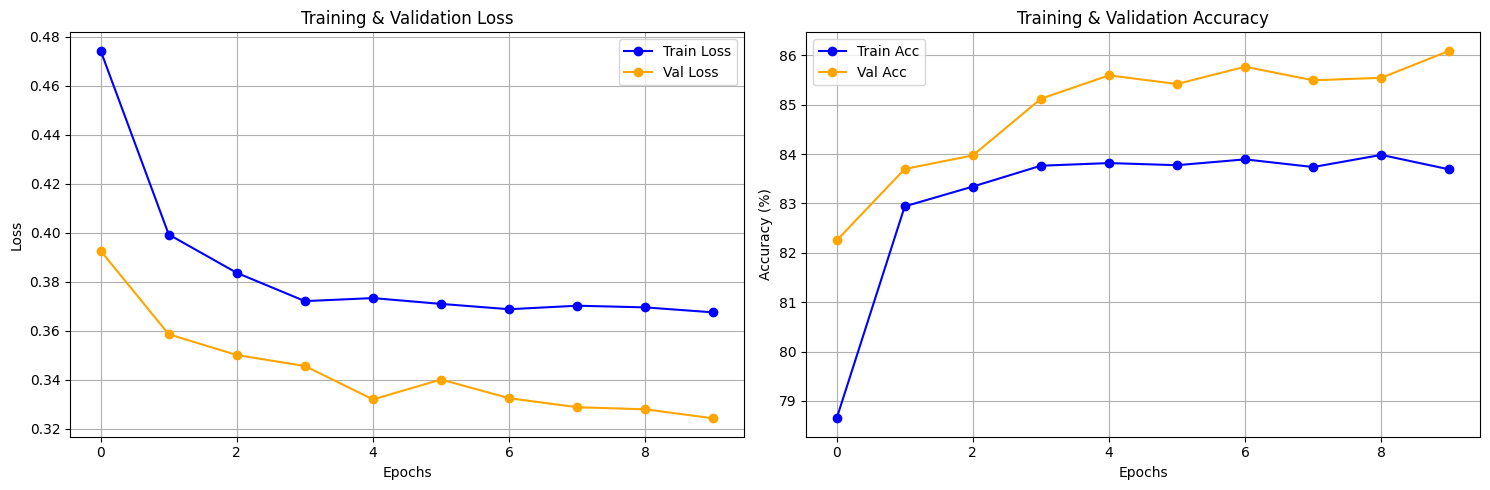

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot Loss
ax1.plot(total_loss_train_plot, label='Train Loss', color='blue', marker='o')
ax1.plot(total_loss_val_plot, label='Val Loss', color='orange', marker='o')
ax1.set_title('Training & Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Plot Accuracy
ax2.plot(total_acc_train_plot, label='Train Acc', color='blue', marker='o')
ax2.plot(total_acc_val_plot, label='Val Acc', color='orange', marker='o')
ax2.set_title('Training & Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()